In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

#Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#Обучение 
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

#Предсказания
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

#Оценка 
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Accuracy: 0.9883
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        64
           1       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171



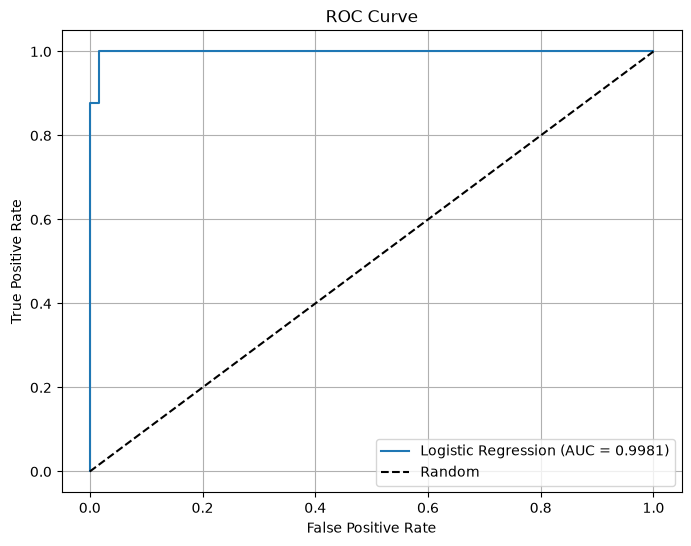

In [11]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpt, tpr, tresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpt, tpr, label=f'Logistic Regression (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
#SVM- линейное ядро
from sklearn.svm import SVC

#Линейный SVM
svm_linear = SVC(kernel='linear', probability=True, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_svm = svm_linear.predict(X_test_scaled)
y_proba_svm = svm_linear.predict_proba(X_test_scaled)[:, 1]

print(f"SVM (linear) Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"SVM (linear) AUC: {roc_auc_score(y_test, y_proba_svm):.4f}")

SVM (linear) Accuracy: 0.9825
SVM (linear) AUC: 0.9947


/home/floppa/Projects/AlgoritmsML/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [13]:
#SVM- RBF-ядро

#SVM с RBF ядром
svm_rbf = SVC(kernel='rbf', gamma='scale', probability=True, random_state=42)
svm_rbf.fit(X_train_scaled, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test_scaled)
y_proba_svm_rbf = svm_rbf.predict_proba(X_test_scaled)[:, 1]

print(f"SVM (RBF) Accuracy: {accuracy_score(y_test, y_pred_svm_rbf):.4f}")
print(f"SVM (RBF) AUC: {roc_auc_score(y_test, y_proba_svm_rbf):.4f}")


SVM (RBF) Accuracy: 0.9766
SVM (RBF) AUC: 0.9978


/home/floppa/Projects/AlgoritmsML/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
